In [1]:
#Importación de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [2]:
#Creación del dataframe oginal de los datos del csv
path="../../data/Obesidad_Infantil.csv"
encoding="latin1"
df=pd.read_csv(path, encoding=encoding)
df.shape

(313, 7)

In [42]:
#Revisamos la matriz de correlaciones de Pearson
df_numeric = df.select_dtypes(include="number")
display(df_numeric.corr())

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
PESO (KG),1.000000,0.830357,0.913062,0.629323,0.511282,0.884710
TALLA (MT),0.830357,1.000000,0.631897,0.855203,0.026385,0.504175
CIRCUNFERENCIA DE CINTURA,0.913062,0.631897,1.000000,0.415179,0.786955,0.930365
EDAD,0.629323,0.855203,0.415179,1.000000,-0.139436,0.312798
ÍNDICE CINTURA/TALLA,0.511282,0.026385,0.786955,-0.139436,1.000000,0.798940
IMC,0.884710,0.504175,0.930365,0.312798,0.798940,1.000000


**Definición del Modelo de Regresión**

Para este ejemplo se considera al PESO (KG) como la variable predictiva.
Las demás variables númericas se consideraran variables explicativas.

De momento lo realizamos sin considerar el valor r de Pearson, ya que buscamos explorar como el incremento de variables explicativas puede terner un impacto sobre r2 del modelo.

In [3]:

y= df["PESO (KG)"]     #(r,)
X = df[['TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD','ÍNDICE CINTURA/TALLA', 'IMC']]    #(r,c)
print(y.shape)
X.shape

(313,)


(313, 5)

In [4]:
#Crear el modelo de Regresion
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.2)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(250, 5) (63, 5) (250,) (63,)


In [15]:
#El modelo se ajusta a los datos de entrada y salida X y y
#model.fit(X,y)      #Posible sobreajuste
model.fit(X_train, y_train)      #Solo se entrena con datos de entrenamiento

LinearRegression()

In [16]:
m = model.coef_
b = model.intercept_
print(f"Valor de m= {m} y valor de b= {b}")

Valor de m= [-1.17210066e+01  1.30833277e+00 -1.04287241e-01 -1.68033221e+02
  1.76675580e+00] y valor de b= 14.658350823374327


Se obtiene la ecuación:

y^i = 14.6583 -11.7210 X1 + 1.3083 X2 -0.1042 X3 -0.0168 X4 + 1.7667 X5

In [17]:
#Calculamos las predicciones 
y_pred = model.predict(X_test)
print(y_pred.shape)
y_pred

(63,)


array([22.16128475, 18.66422934, 25.64104358, 27.02272954, 17.17420704,
       17.62649217, 43.51406655, 29.43345798, 40.93046681, 44.57780952,
       35.58475906, 20.58904532, 26.50580465, 44.3710476 , 39.08033557,
       26.49792578, 14.83371091, 26.05856348, 21.53859784, 32.45742656,
       20.12575156, 47.91217464, 38.1596496 , 37.39113957, 30.65444655,
       31.28353475, 30.07217594, 28.15530314, 20.54969134, 38.09185429,
       47.34791084, 27.67951464, 10.4428487 , 38.30363443, 24.1648274 ,
       20.02638808, 42.47194549, 27.67635336, 19.49275761, 40.08036088,
       17.29727141, 31.81695332, 16.61632018, 21.04335786, 34.84818938,
       37.22182157, 59.02879263, 42.40380371, 12.46336592, 36.79500687,
       24.95883956, 23.22720841, 28.83049026, 52.48855471, 21.20223703,
       29.61795796, 37.75371098, 25.39149419, 30.76654818, 46.31347119,
       46.9915803 , 41.21330517, 33.72933195])

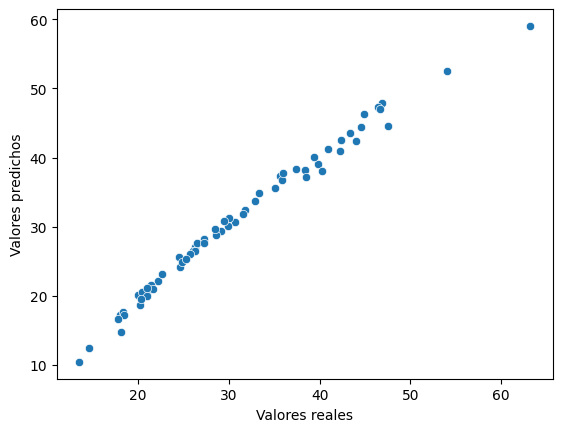

In [12]:
#Visualizar la eficacia de las predicciones
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.show()

Se observa un mejor ajuste de las predicciones respecto a los valores reales de y.

De momento se asume una mejora del modelo no considerando el cumplimiento de los supuestos de Linealidad.

In [14]:
r2= r2_score(y_test,y_pred)
mae= mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)

In [52]:
print(f"Valor de r2: {r2}, valor de mae: {mae} y valor de mse: {mse}")

Valor de r2: 0.9855786502833768, valor de mae: 0.9343554637397584 y valor de mse: 1.5842193485732188


In [ ]:
#Guardar el modelo con sus pesos, metricas, conjuntos de prueba
import joblib

#Crear diccionario

artifacts = {
    "model":model,
    "metrics":{
        "r2":r2,
        "mae":mae,
        "mse":mse
    },
    "features_names":list(X.columns),
    "X_test":X_test,
    "y_test":y_test,
    "y_pred":y_pred
}

#Asignamos la ruta de guardado
joblib.dump(artifacts, "../models/multilinear_regression_model.joblib")



['../../models/multilinear_regression_model.joblib']

**Tarea**
10 preguntas y respuestas sobre "Analisis de residuos en Regresion" a mano.